In [21]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops, find_contours
from skimage.morphology import convex_hull_image
from skimage.feature import graycomatrix, graycoprops
from scipy.stats import skew, kurtosis
from scipy.fft import fft

BASE_DIR = "Berhasil"
FOLDER_MASK = os.path.join(BASE_DIR, "Hasil_Segmentasi", "Mask_Biner")
FOLDER_SEG  = os.path.join(BASE_DIR, "Hasil_Segmentasi", "Objek_RGB")
FOLDER_GT   = os.path.join(BASE_DIR, "Datasets", "Masks")

# Cek ketersediaan folder
for f in [FOLDER_MASK, FOLDER_SEG, FOLDER_GT]:
    assert os.path.isdir(f), f"Folder tidak ditemukan: {f}"

# --- Ambil sampel dengan mencocokkan nama file dengan benar ---
# Ambil satu file mask
mask_files = sorted(os.listdir(FOLDER_MASK))
if len(mask_files) == 0:
    raise ValueError("Folder Mask_Biner kosong! Jalankan Percobaan 1 dulu.")

SAMPLE_FILE = mask_files[0]
STEM = SAMPLE_FILE.replace('_mask.png', '')  # Nama tanpa _mask

# Muat mask dan seg
mask = cv2.imread(os.path.join(FOLDER_MASK, SAMPLE_FILE), cv2.IMREAD_GRAYSCALE)
seg  = cv2.imread(os.path.join(FOLDER_SEG, SAMPLE_FILE.replace('_mask.png', '_seg.png')))
seg  = cv2.cvtColor(seg, cv2.COLOR_BGR2RGB)

# --- Cari file GT yang cocok (tanpa peduli ekstensi) ---
gt_path = None
for ext in ['.png', '.jpg', '.jpeg']:
    potential_gt = os.path.join(FOLDER_GT, STEM + ext)
    if os.path.exists(potential_gt):
        gt_path = potential_gt
        break

if gt_path is None:
    raise FileNotFoundError(f"Ground Truth untuk {STEM} tidak ditemukan di {FOLDER_GT}")

gt = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)
print(f"Sampel: {STEM}")
print(f"GT Path: {gt_path}")
print(f"Ukuran Mask: {mask.shape}, Seg: {seg.shape}, GT: {gt.shape}")

Sampel: cju0sxqiclckk08551ycbwhno
GT Path: Berhasil\Datasets\Masks\cju0sxqiclckk08551ycbwhno.jpg
Ukuran Mask: (531, 570), Seg: (531, 570, 3), GT: (531, 570)


STAGE 1: METRIK EVALUASI SEGMENTASI (Baseline)

Cell 2: Hitung IoU, Dice, Precision, Recall & Visualisasi

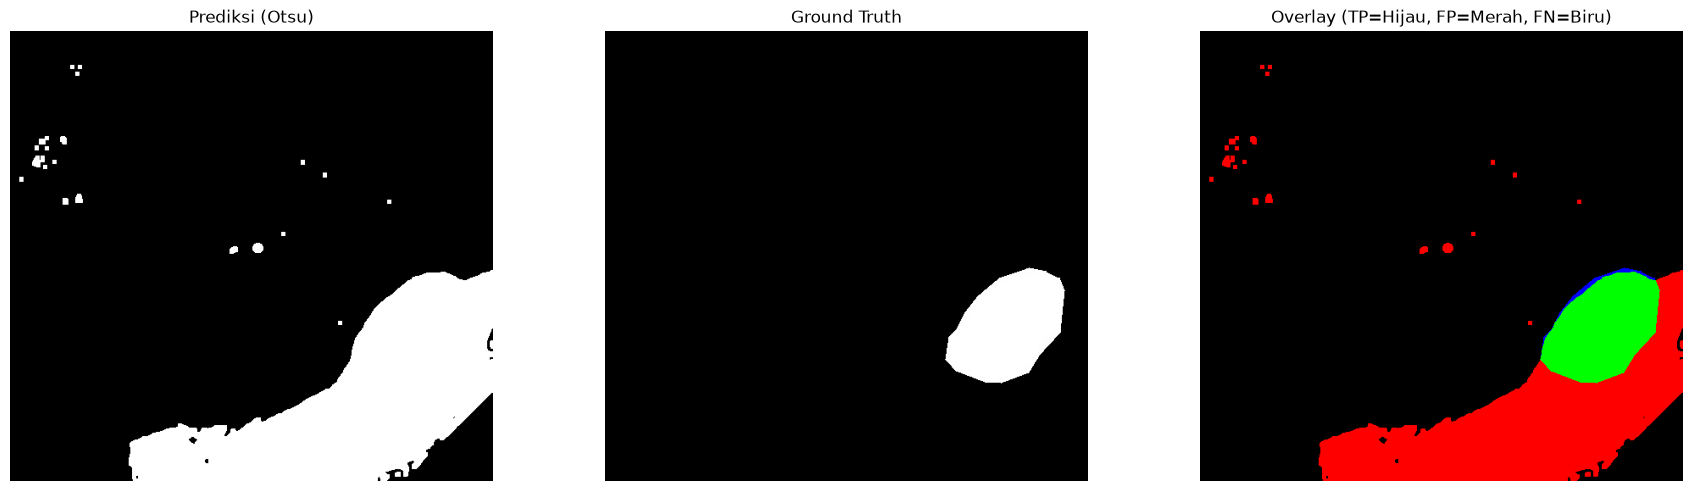

IoU: 0.2371 | Dice: 0.3834 | Precision: 0.2394 | Recall: 0.9610


In [22]:
def evaluate_mask(pred, gt):
    p = (pred > 127).astype(np.uint8)
    g = (gt   > 127).astype(np.uint8)
    inter = np.logical_and(p, g).sum()
    union = np.logical_or(p, g).sum()
    iou  = inter / union if union > 0 else 0.0
    dice = 2 * inter / (p.sum() + g.sum()) if (p.sum() + g.sum()) > 0 else 0.0
    prec = inter / p.sum() if p.sum() > 0 else 0.0
    rec  = inter / g.sum() if g.sum() > 0 else 0.0
    return {"IoU": iou, "Dice": dice, "Precision": prec, "Recall": rec}

metrics = evaluate_mask(mask, gt)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(mask, cmap='gray'); axes[0].set_title("Prediksi (Otsu)"); axes[0].axis('off')
axes[1].imshow(gt, cmap='gray');   axes[1].set_title("Ground Truth");  axes[1].axis('off')

# Visualisasi Overlay Intersection
overlay = np.zeros((*mask.shape, 3), dtype=np.uint8)
overlay[(mask > 127) & (gt > 127)] = [0, 255, 0]   # True Positive (Hijau)
overlay[(mask > 127) & (gt <= 127)] = [255, 0, 0]  # False Positive (Merah)
overlay[(mask <= 127) & (gt > 127)] = [0, 0, 255]  # False Negative (Biru)
axes[2].imshow(overlay); axes[2].set_title("Overlay (TP=Hijau, FP=Merah, FN=Biru)"); axes[2].axis('off')

plt.tight_layout(); plt.show()

print(f"IoU: {metrics['IoU']:.4f} | Dice: {metrics['Dice']:.4f} | Precision: {metrics['Precision']:.4f} | Recall: {metrics['Recall']:.4f}")

STAGE 2: FITUR MORFOLOGI / GEOMETRI (Bertahap)

Cell 3: Visualisasi Bounding Box, Convex Hull, Sumbu Utama

C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_27996\1675878716.py:43: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  x1 = x0 - 0.5 * polip.major_axis_length * np.sin(orientation)
C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_27996\1675878716.py:44: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  y1 = y0 + 0.5 * polip.major_axis_length * np.cos(orientation)
C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_27996\1675878716.py:45: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  x2 = x0 + 0.5 * polip.major_axis_length * np.sin(orientation)
C:\Users\Talitha Sukma\AppData\Local\Temp\ipyk

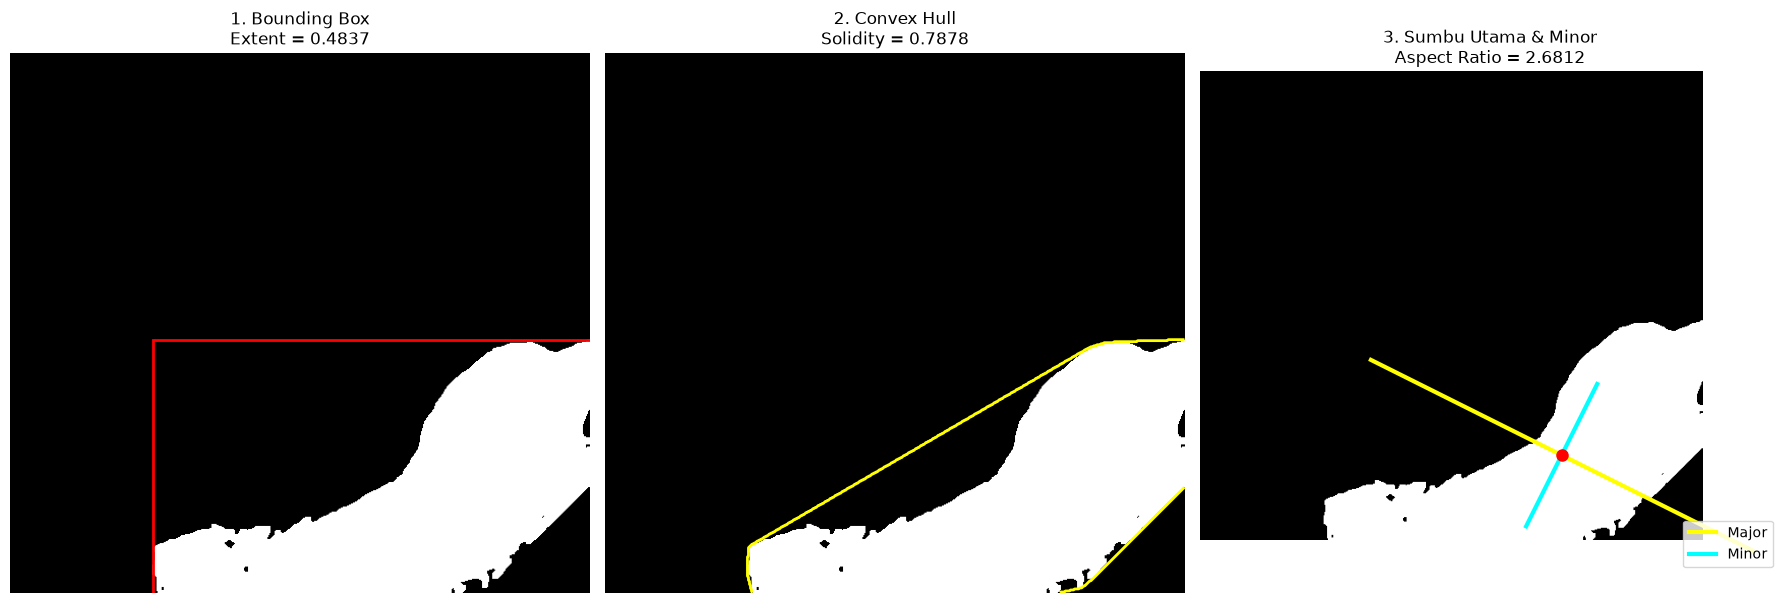

In [23]:
from skimage.measure import label, regionprops
from skimage.morphology import convex_hull_image

# 1. Buat citra biner dari mask & ambil region objek (polip)
binary = (mask > 127).astype(np.uint8)
labeled_img = label(binary)
regions = regionprops(labeled_img)

if len(regions) == 0:
    raise ValueError("Tidak ada objek terdeteksi pada mask biner.")

# Ambil region dengan luas (area) terbesar sebagai objek utama
polip = max(regions, key=lambda r: r.area)

# Opsional: jika ingin fokus hanya pada region polip terbesar saja
binary_polip = (labeled_img == polip.label).astype(np.uint8)

# 2. Visualisasi fitur bentuk
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# (1) Bounding Box
ax = axes[0]
ax.imshow(binary_polip, cmap='gray')
minr, minc, maxr, maxc = polip.bbox
rect = plt.Rectangle((minc, minr), maxc - minc, maxr - minr, fill=False, edgecolor='red', linewidth=2)
ax.add_patch(rect)
ax.set_title(f"1. Bounding Box\nExtent = {polip.extent:.4f}")
ax.axis('off')

# (2) Convex Hull
ax = axes[1]
hull = convex_hull_image(binary_polip)
ax.imshow(binary_polip, cmap='gray')
ax.contour(hull, colors='yellow', linewidths=2)
ax.set_title(f"2. Convex Hull\nSolidity = {polip.solidity:.4f}")
ax.axis('off')

# (3) Sumbu Utama & Minor
ax = axes[2]
ax.imshow(binary_polip, cmap='gray')
y0, x0 = polip.centroid
orientation = polip.orientation
x1 = x0 - 0.5 * polip.major_axis_length * np.sin(orientation)
y1 = y0 + 0.5 * polip.major_axis_length * np.cos(orientation)
x2 = x0 + 0.5 * polip.major_axis_length * np.sin(orientation)
y2 = y0 - 0.5 * polip.major_axis_length * np.cos(orientation)
ax.plot([x1, x2], [y1, y2], '-', color='yellow', linewidth=3, label='Major')

x3 = x0 - 0.5 * polip.minor_axis_length * np.cos(orientation)
y3 = y0 - 0.5 * polip.minor_axis_length * np.sin(orientation)
x4 = x0 + 0.5 * polip.minor_axis_length * np.cos(orientation)
y4 = y0 + 0.5 * polip.minor_axis_length * np.sin(orientation)
ax.plot([x3, x4], [y3, y4], '-', color='cyan', linewidth=3, label='Minor')

ax.plot(x0, y0, 'ro', markersize=8)
aspect_ratio = polip.major_axis_length / polip.minor_axis_length if polip.minor_axis_length > 0 else 0.0
ax.set_title(f"3. Sumbu Utama & Minor\nAspect Ratio = {aspect_ratio:.4f}")
ax.legend(loc='lower right')
ax.axis('off')

plt.tight_layout()
plt.show()

Cell 4: Tabel Hitungan Fitur Morfologi Dasar

In [24]:
shape_data = {
    "Area": polip.area,
    "Perimeter": polip.perimeter,
    "Circularity": (4 * np.pi * polip.area) / (polip.perimeter ** 2) if polip.perimeter > 0 else 0,
    "Aspect_Ratio": polip.major_axis_length / polip.minor_axis_length if polip.minor_axis_length > 0 else 0,
    "Solidity": polip.solidity,
    "Extent": polip.extent,
    "Major_Axis": polip.major_axis_length,
    "Minor_Axis": polip.minor_axis_length,
    "Orientation_deg": np.degrees(polip.orientation),
    "Feret_Max": polip.feret_diameter_max,
    "Eccentricity": polip.eccentricity,
    "Equivalent_Diameter": polip.equivalent_diameter_area
}
print(pd.DataFrame([shape_data]).T.rename(columns={0: "Nilai"}))

                            Nilai
Area                 51786.000000
Perimeter             1408.572727
Circularity              0.327992
Aspect_Ratio             2.681157
Solidity                 0.787811
Extent                   0.483665
Major_Axis             482.991407
Minor_Axis             180.142908
Orientation_deg        -63.460551
Feret_Max              492.427660
Eccentricity             0.927842
Equivalent_Diameter    256.780029


C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_27996\1216522827.py:5: FutureWarning: `RegionProperties.minor_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_minor_length` instead. 
  "Aspect_Ratio": polip.major_axis_length / polip.minor_axis_length if polip.minor_axis_length > 0 else 0,
C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_27996\1216522827.py:5: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  "Aspect_Ratio": polip.major_axis_length / polip.minor_axis_length if polip.minor_axis_length > 0 else 0,
C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_27996\1216522827.py:8: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  "Major_Axis": polip.major

 STAGE 3: FITUR MOMEN (Hu Moments, Zernike, Fourier)
 
Cell 5: Hu Moments (7 Nilai Invarian terhadap Rotasi/Skala)

In [25]:
def hu_moments(mask):
    m = cv2.moments(mask, binaryImage=True)
    hu = cv2.HuMoments(m).flatten()
    # Transformasi log agar skalanya seimbang (karena nilainya sangat kecil)
    return -np.sign(hu) * np.log10(np.abs(hu) + 1e-30)

hu = hu_moments(binary)
hu_df = pd.DataFrame(hu, columns=["Hu Moment (Log)"], index=[f"h{i+1}" for i in range(7)])
print(hu_df)

    Hu Moment (Log)
h1         0.439540
h2         1.401622
h3         3.067580
h4         1.684763
h5         4.118397
h6         3.586408
h7        -4.377720


Cell 6: Fourier Descriptor (Bentuk Kontur)

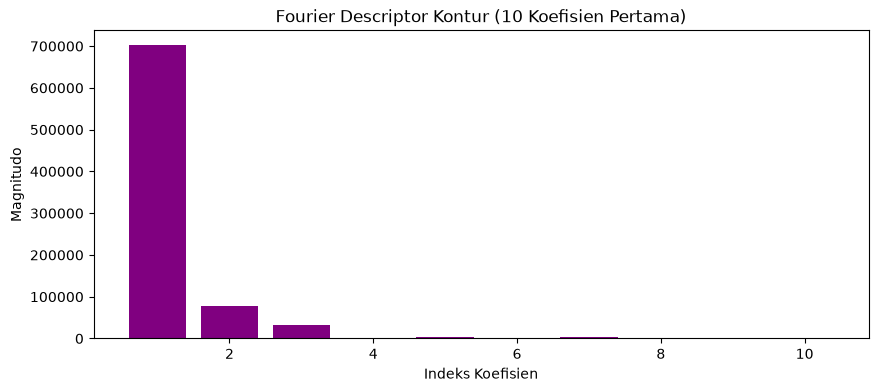

Fourier Descriptor (10): [702266.64  78074.41  31181.19   2040.12   2686.     1063.61   3723.98
   2109.3    1516.51   1268.77]


In [26]:
# Ambil kontur terbesar
contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
c = max(contours, key=cv2.contourArea).squeeze()
# Koordinat kompleks: x + iy
z = c[:, 0] + 1j * c[:, 1]
# FFT
f_descriptors = np.abs(fft(z))
# Ambil 10 koefisien pertama (biasanya paling informatif)
f_desc_10 = f_descriptors[:10]

fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.bar(range(1, 11), f_desc_10, color='purple')
ax.set_title("Fourier Descriptor Kontur (10 Koefisien Pertama)")
ax.set_xlabel("Indeks Koefisien"); ax.set_ylabel("Magnitudo")
plt.show()

print("Fourier Descriptor (10):", np.round(f_desc_10, 2))

STAGE 4: FITUR TEKSTUR (GLCM & Statistik Orde 1)

Cell 7: GLCM (Gray Level Co-occurrence Matrix)

                       Nilai
GLCM_Contrast       1.435381
GLCM_Dissimilarity  0.143307
GLCM_Homogeneity    0.966435
GLCM_Energy         0.806284
GLCM_Correlation    0.991350
GLCM_ASM            0.650094


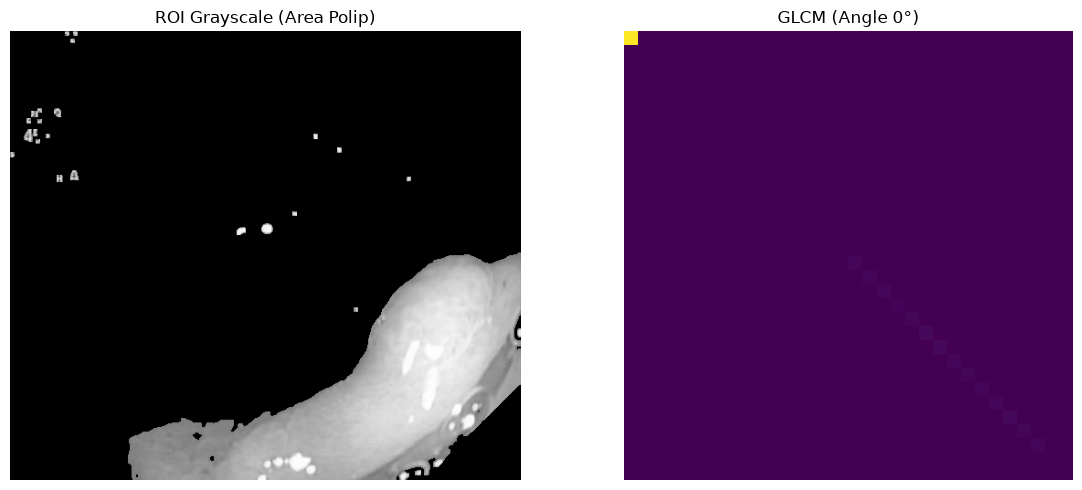

In [27]:
gray_img = cv2.cvtColor(seg, cv2.COLOR_RGB2GRAY)
x, y, w, h = cv2.boundingRect(mask)
roi_gray = gray_img[y:y+h, x:x+w]
roi_mask = mask[y:y+h, x:x+w]

# Kuantisasi 32 level
roi_quant = (roi_gray // 8).astype(np.uint8)
glcm = graycomatrix(roi_quant, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4], levels=32, symmetric=True, normed=True)

texture_data = {
    "GLCM_Contrast": graycoprops(glcm, 'contrast').mean(),
    "GLCM_Dissimilarity": graycoprops(glcm, 'dissimilarity').mean(),
    "GLCM_Homogeneity": graycoprops(glcm, 'homogeneity').mean(),
    "GLCM_Energy": graycoprops(glcm, 'energy').mean(),
    "GLCM_Correlation": graycoprops(glcm, 'correlation').mean(),
    "GLCM_ASM": graycoprops(glcm, 'ASM').mean(),
}
print(pd.DataFrame([texture_data]).T.rename(columns={0: "Nilai"}))

# Visualisasi GLCM Matrix
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(roi_gray, cmap='gray'); ax[0].set_title("ROI Grayscale (Area Polip)"); ax[0].axis('off')
ax[1].imshow(np.log1p(glcm[:, :, 0, 0]), cmap='viridis'); ax[1].set_title("GLCM (Angle 0°)"); ax[1].axis('off')
plt.tight_layout(); plt.show()

Cell 8: Statistik Orde Pertama

               Nilai
Mean      184.233968
Std        34.504141
Skewness    0.048189
Kurtosis   -1.031251
Min        72.000000
Max       255.000000


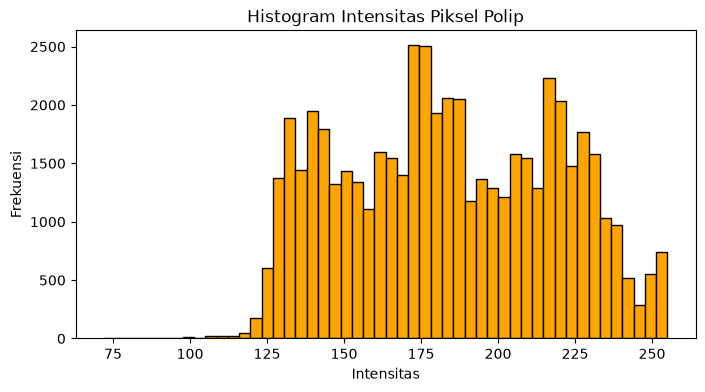

In [28]:
roi_pixels = gray_img[mask > 127]
first_order = {
    "Mean": np.mean(roi_pixels),
    "Std": np.std(roi_pixels),
    "Skewness": skew(roi_pixels),
    "Kurtosis": kurtosis(roi_pixels),
    "Min": np.min(roi_pixels),
    "Max": np.max(roi_pixels),
}
print(pd.DataFrame([first_order]).T.rename(columns={0: "Nilai"}))

# Visualisasi Histogram
plt.figure(figsize=(8, 4))
plt.hist(roi_pixels, bins=50, color='orange', edgecolor='black')
plt.title("Histogram Intensitas Piksel Polip")
plt.xlabel("Intensitas"); plt.ylabel("Frekuensi")
plt.show()

STAGE 5: BANDINGKAN & SIMPAN SEMUA FITUR (Untuk Batch)

Cell 9: Fungsi Komprehensif & Proses Batch Semua Gambar

In [29]:
def extract_all_features(mask_path, seg_path, gt_path):
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    seg  = cv2.imread(seg_path)
    gt   = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)
    
    # Cek jika salah satu gagal dibaca
    if mask is None or seg is None or gt is None:
        return None, "File gagal dibaca (None)"

    seg_rgb = cv2.cvtColor(seg, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(seg, cv2.COLOR_RGB2GRAY)
    binary = (mask > 127).astype(np.uint8)
    
    # Region (Pastikan ada objek)
    labeled = label(binary)
    regions = regionprops(labeled)
    if len(regions) == 0: 
        return None, "Mask kosong (tidak ada objek)"
    polip = max(regions, key=lambda r: r.area)

    # 1. Evaluasi
    m = evaluate_mask(mask, gt)

    # 2. Morfologi
    shape = {
        "Area": polip.area, "Perimeter": polip.perimeter,
        "Circularity": (4*np.pi*polip.area)/(polip.perimeter**2) if polip.perimeter>0 else 0,
        "Aspect_Ratio": polip.major_axis_length/polip.minor_axis_length if polip.minor_axis_length>0 else 0,
        "Solidity": polip.solidity, "Extent": polip.extent,
        "Major_Axis": polip.major_axis_length, "Minor_Axis": polip.minor_axis_length,
        "Orientation": np.degrees(polip.orientation), "Feret_Max": polip.feret_diameter_max,
        "Eccentricity": polip.eccentricity, "Equivalent_Diameter": polip.equivalent_diameter_area
    }

    # 3. Hu Moments
    hu = hu_moments(binary)
    for i, val in enumerate(hu): shape[f"Hu_{i+1}"] = val

    # 4. Fourier Descriptor (10)
    contours, _ = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    if contours:
        c = max(contours, key=cv2.contourArea).squeeze()
        # Pastikan c adalah array 2D
        if c.ndim == 1:
            c = c.reshape(-1, 2)
        z = c[:, 0] + 1j * c[:, 1]
        fd = np.abs(fft(z))[:10]
        for i, val in enumerate(fd): shape[f"Fourier_{i+1}"] = val

    # 5. GLCM
    x, y, w, h = cv2.boundingRect(mask)
    roi_gray = gray[y:y+h, x:x+w]
    roi_quant = (roi_gray // 8).astype(np.uint8)
    glcm = graycomatrix(roi_quant, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4], levels=32, symmetric=True, normed=True)
    texture = {
        "GLCM_Contrast": graycoprops(glcm, 'contrast').mean(),
        "GLCM_Dissimilarity": graycoprops(glcm, 'dissimilarity').mean(),
        "GLCM_Homogeneity": graycoprops(glcm, 'homogeneity').mean(),
        "GLCM_Energy": graycoprops(glcm, 'energy').mean(),
        "GLCM_Correlation": graycoprops(glcm, 'correlation').mean(),
    }

    # 6. Statistik Orde 1
    roi_pixels = gray[mask > 127]
    stat1 = {
        "Mean": np.mean(roi_pixels), "Std": np.std(roi_pixels),
        "Skewness": skew(roi_pixels), "Kurtosis": kurtosis(roi_pixels),
        "Min": np.min(roi_pixels), "Max": np.max(roi_pixels)
    }

    # Gabung
    row = {"Filename": os.path.basename(mask_path).replace("_mask.png", "")}
    row.update(m); row.update(shape); row.update(texture); row.update(stat1)
    return row, None

# --- PROSES BATCH ---
all_rows = []
failed_files = []
files = sorted(os.listdir(FOLDER_MASK))
print(f"Memproses {len(files)} gambar...\n")

for f in files:
    stem = f.replace('_mask.png', '')
    mask_path = os.path.join(FOLDER_MASK, f)
    seg_path  = os.path.join(FOLDER_SEG, stem + '_seg.png')
    
    # Cari GT dengan ekstensi yang cocok
    gt_path = None
    for ext in ['.png', '.jpg', '.jpeg']:
        potential = os.path.join(FOLDER_GT, stem + ext)
        if os.path.exists(potential):
            gt_path = potential
            break
            
    if gt_path is None:
        failed_files.append(f"{stem} (GT tidak ditemukan)")
        continue

    row, error_msg = extract_all_features(mask_path, seg_path, gt_path)
    
    if row:
        all_rows.append(row)
    else:
        failed_files.append(f"{stem} ({error_msg})")

# Simpan ke CSV jika ada data
if all_rows:
    df_all = pd.DataFrame(all_rows)
    output_csv = os.path.join(BASE_DIR, "fitur_lengkap_polip.csv")
    df_all.to_csv(output_csv, index=False)
    print(f"\n✅ Selesai! File disimpan: {output_csv}")
    print(f"Total gambar diproses: {len(df_all)}")
    print(f"Total fitur diekstrak: {df_all.shape[1] - 1} kolom")
    print("\nContoh 5 baris pertama:")
    display(df_all.head())
else:
    print("\n❌ Tidak ada data yang berhasil diekstrak.")
    print("Cek file yang gagal diproses:")

if failed_files:
    print(f"\n⚠️ {len(failed_files)} file gagal diproses:")
    for ff in failed_files[:10]:  # Tampilkan maks 10
        print(f"  - {ff}")
    if len(failed_files) > 10:
        print(f"  ... dan {len(failed_files)-10} lainnya")

Memproses 25 gambar...



C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_27996\800717114.py:28: FutureWarning: `RegionProperties.minor_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_minor_length` instead. 
  "Aspect_Ratio": polip.major_axis_length/polip.minor_axis_length if polip.minor_axis_length>0 else 0,
C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_27996\800717114.py:28: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  "Aspect_Ratio": polip.major_axis_length/polip.minor_axis_length if polip.minor_axis_length>0 else 0,
C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_27996\800717114.py:30: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  "Major_Axis": polip.major_axis_le


✅ Selesai! File disimpan: Berhasil\fitur_lengkap_polip.csv
Total gambar diproses: 25
Total fitur diekstrak: 44 kolom

Contoh 5 baris pertama:


,Filename,IoU,Dice,Precision,Recall,Area,Perimeter,Circularity,Aspect_Ratio,Solidity,...,GLCM_Dissimilarity,GLCM_Homogeneity,GLCM_Energy,GLCM_Correlation,Mean,Std,Skewness,Kurtosis,Min,Max
0,cju0sxqiclckk08551ycbwhno,0.237131,0.383356,0.239437,0.960966,51786.0,1408.572727,0.327992,2.681157,0.787811,...,0.140012,0.964241,0.806161,0.991474,165.565195,39.856662,0.317392,-0.986346,63,255
1,cju1c0qb4tzi308355wtsnp0y,0.651271,0.788812,0.673275,0.952216,162335.0,2880.535280,0.245853,1.333935,0.719934,...,0.334099,0.902296,0.465467,0.985434,126.213028,27.182405,1.531201,4.223857,50,254
2,cju1c6yfz42md08550zgoz3pw,0.527446,0.690625,0.644649,0.743661,86278.0,1790.444876,0.338211,1.556050,0.874640,...,0.240099,0.927684,0.627517,0.988031,126.288774,26.971854,1.648842,4.995944,50,255
3,cju1cj3f0qi5n0993ut8f49rj,0.830749,0.907551,0.917383,0.897927,73040.0,2005.160605,0.228282,1.414812,0.849905,...,0.334430,0.909809,0.618961,0.986958,159.005854,36.202631,0.354201,-0.746738,35,253
4,cju1f15k3w4ct0835cmde6ypo,0.591021,0.742946,0.626574,0.912403,53672.0,2039.391052,0.162165,1.322639,0.803858,...,0.397323,0.920008,0.762137,0.970544,165.692448,33.600306,0.337803,-0.538647,32,254


STAGE 6: ANALISIS MANA FITUR YANG PALING BAGUS
Cell 10: Korelasi & Variance (Fitur yang bagus = variasinya tinggi & tidak saling tumpang tindih)

Top 15 Fitur dengan Variance Tertinggi (Paling Bervariasi):
Fourier_1     2.295116e+11
Area          2.516496e+09
Fourier_2     8.909165e+08
Fourier_3     4.770215e+08
Fourier_4     2.086499e+08
Fourier_5     1.270777e+08
Fourier_6     5.038440e+07
Fourier_7     4.165198e+07
Fourier_8     2.277212e+07
Fourier_10    1.890567e+07
Fourier_9     1.108511e+07
Perimeter     6.427737e+05
Major_Axis    1.008311e+04
Feret_Max     9.883921e+03
Minor_Axis    7.084320e+03
dtype: float64


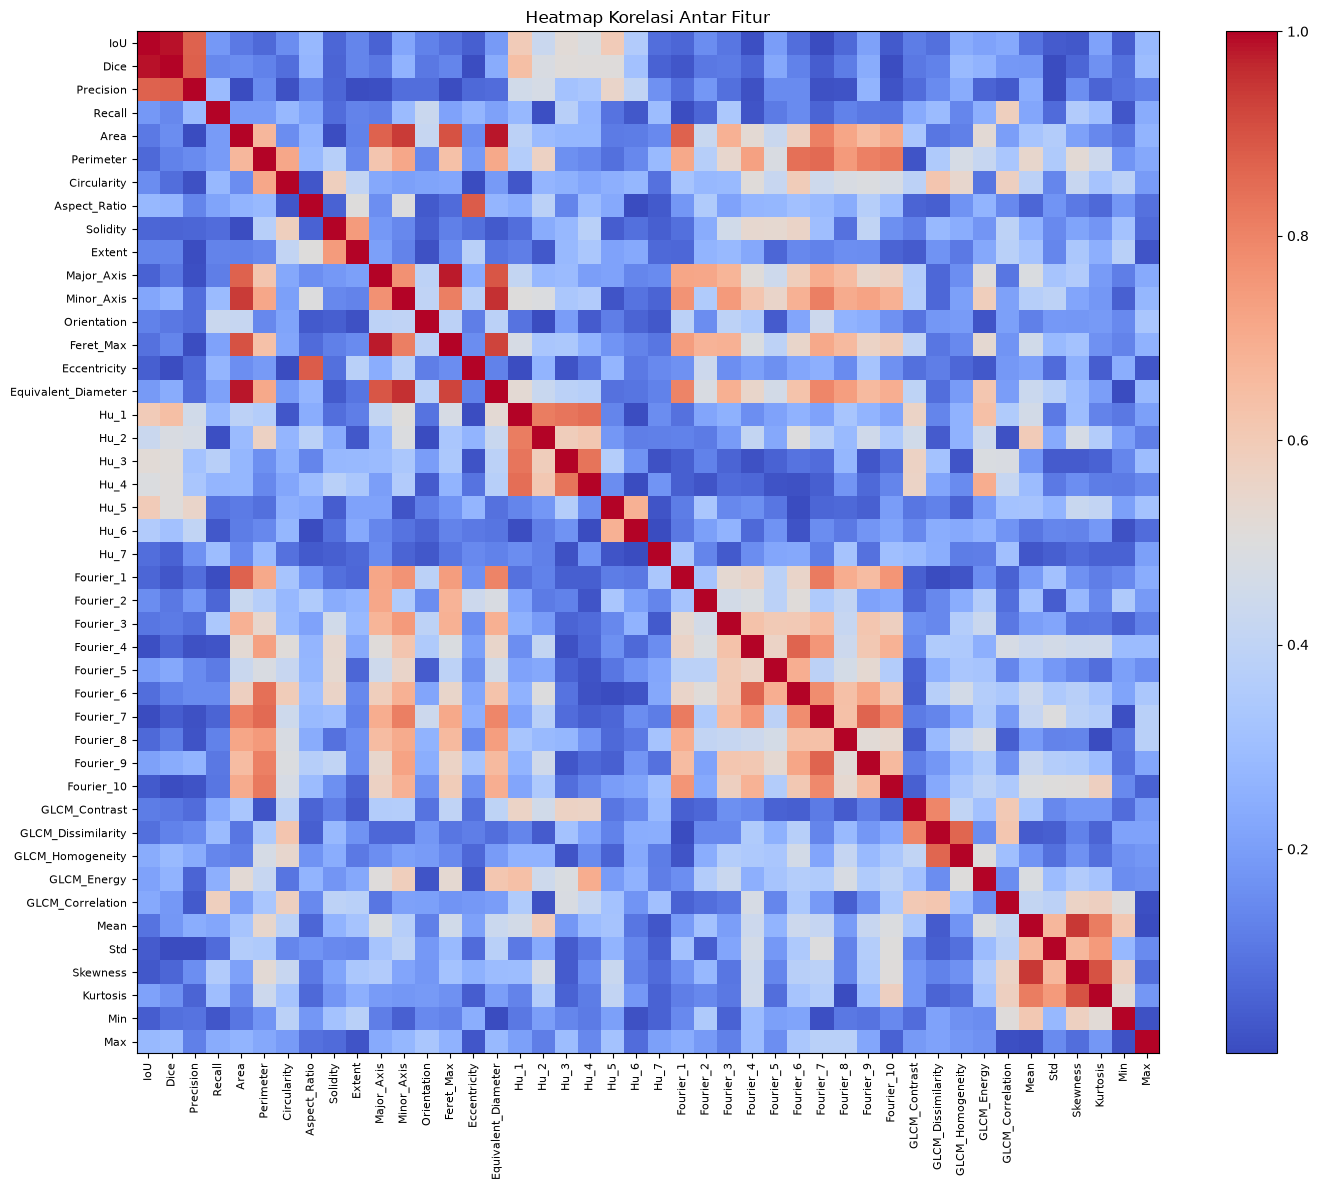

In [30]:
# Hapus kolom non-numerik
df_num = df_all.select_dtypes(include=[np.number])

# 1. Cek Variance (Fitur dengan variance ~0 tidak berguna karena semua gambar nilainya sama)
variance = df_num.var().sort_values(ascending=False)
print("Top 15 Fitur dengan Variance Tertinggi (Paling Bervariasi):")
print(variance.head(15))

# 2. Heatmap Korelasi (Cari fitur yang saling redundan)
corr = df_num.corr().abs()
plt.figure(figsize=(15, 12))
plt.imshow(corr, cmap='coolwarm', interpolation='nearest')
plt.colorbar()
plt.title("Heatmap Korelasi Antar Fitur")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90, fontsize=8)
plt.yticks(range(len(corr.columns)), corr.columns, fontsize=8)
plt.tight_layout(); plt.show()

Cell 11: Uji Statistik (Mana Fitur yang Signifikan?)

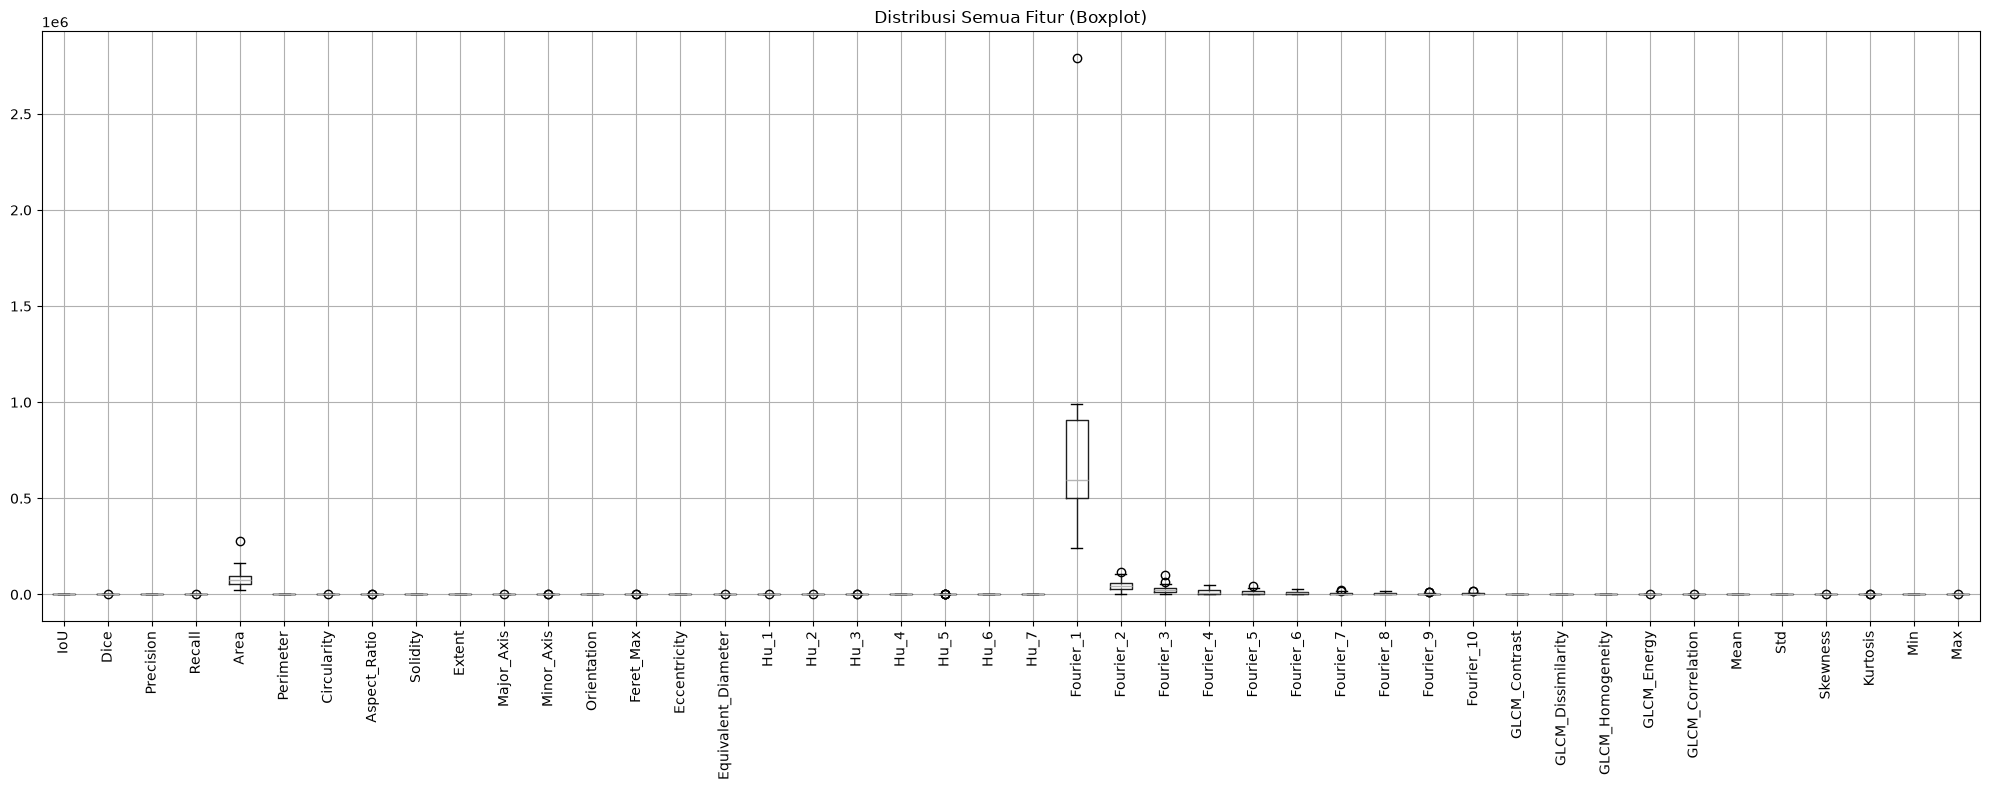

In [31]:
# Contoh: Boxplot semua fitur untuk melihat sebaran
# (Kalau gambar sedikit, boxplot tetap membantu melihat outlier)
df_num.boxplot(figsize=(20, 8), rot=90)
plt.title("Distribusi Semua Fitur (Boxplot)")
plt.tight_layout(); plt.show()

Total data: 25 gambar
Total fitur: 44 kolom



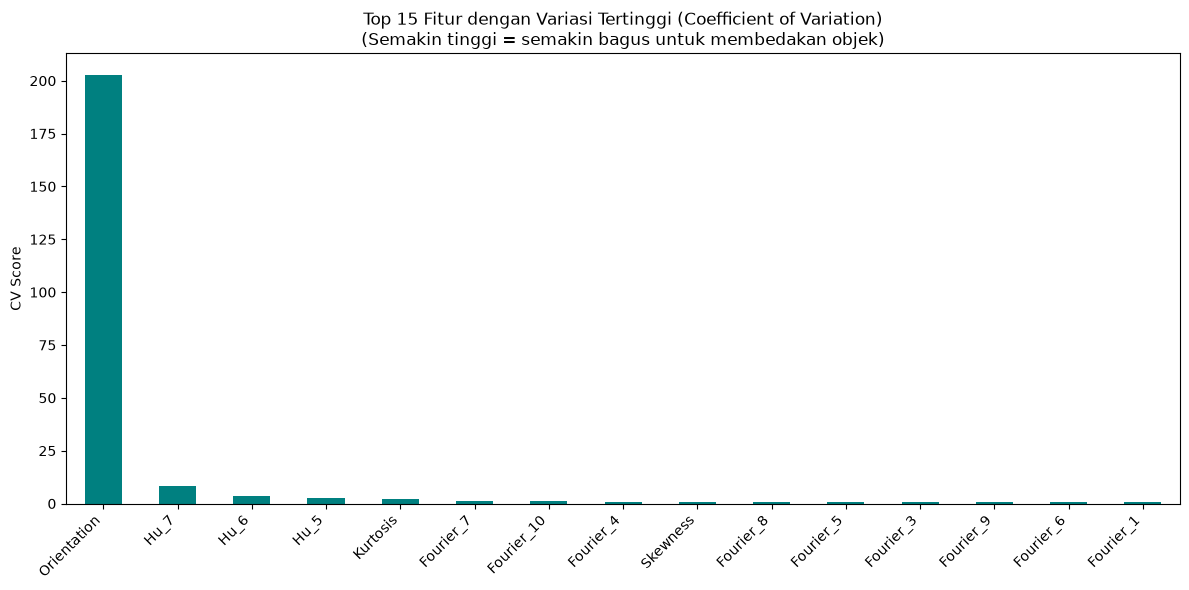

5 Fitur Paling Bervariasi:
Orientation    202.805801
Hu_7             8.516781
Hu_6             3.559517
Hu_5             2.811551
Kurtosis         1.975958
dtype: float64




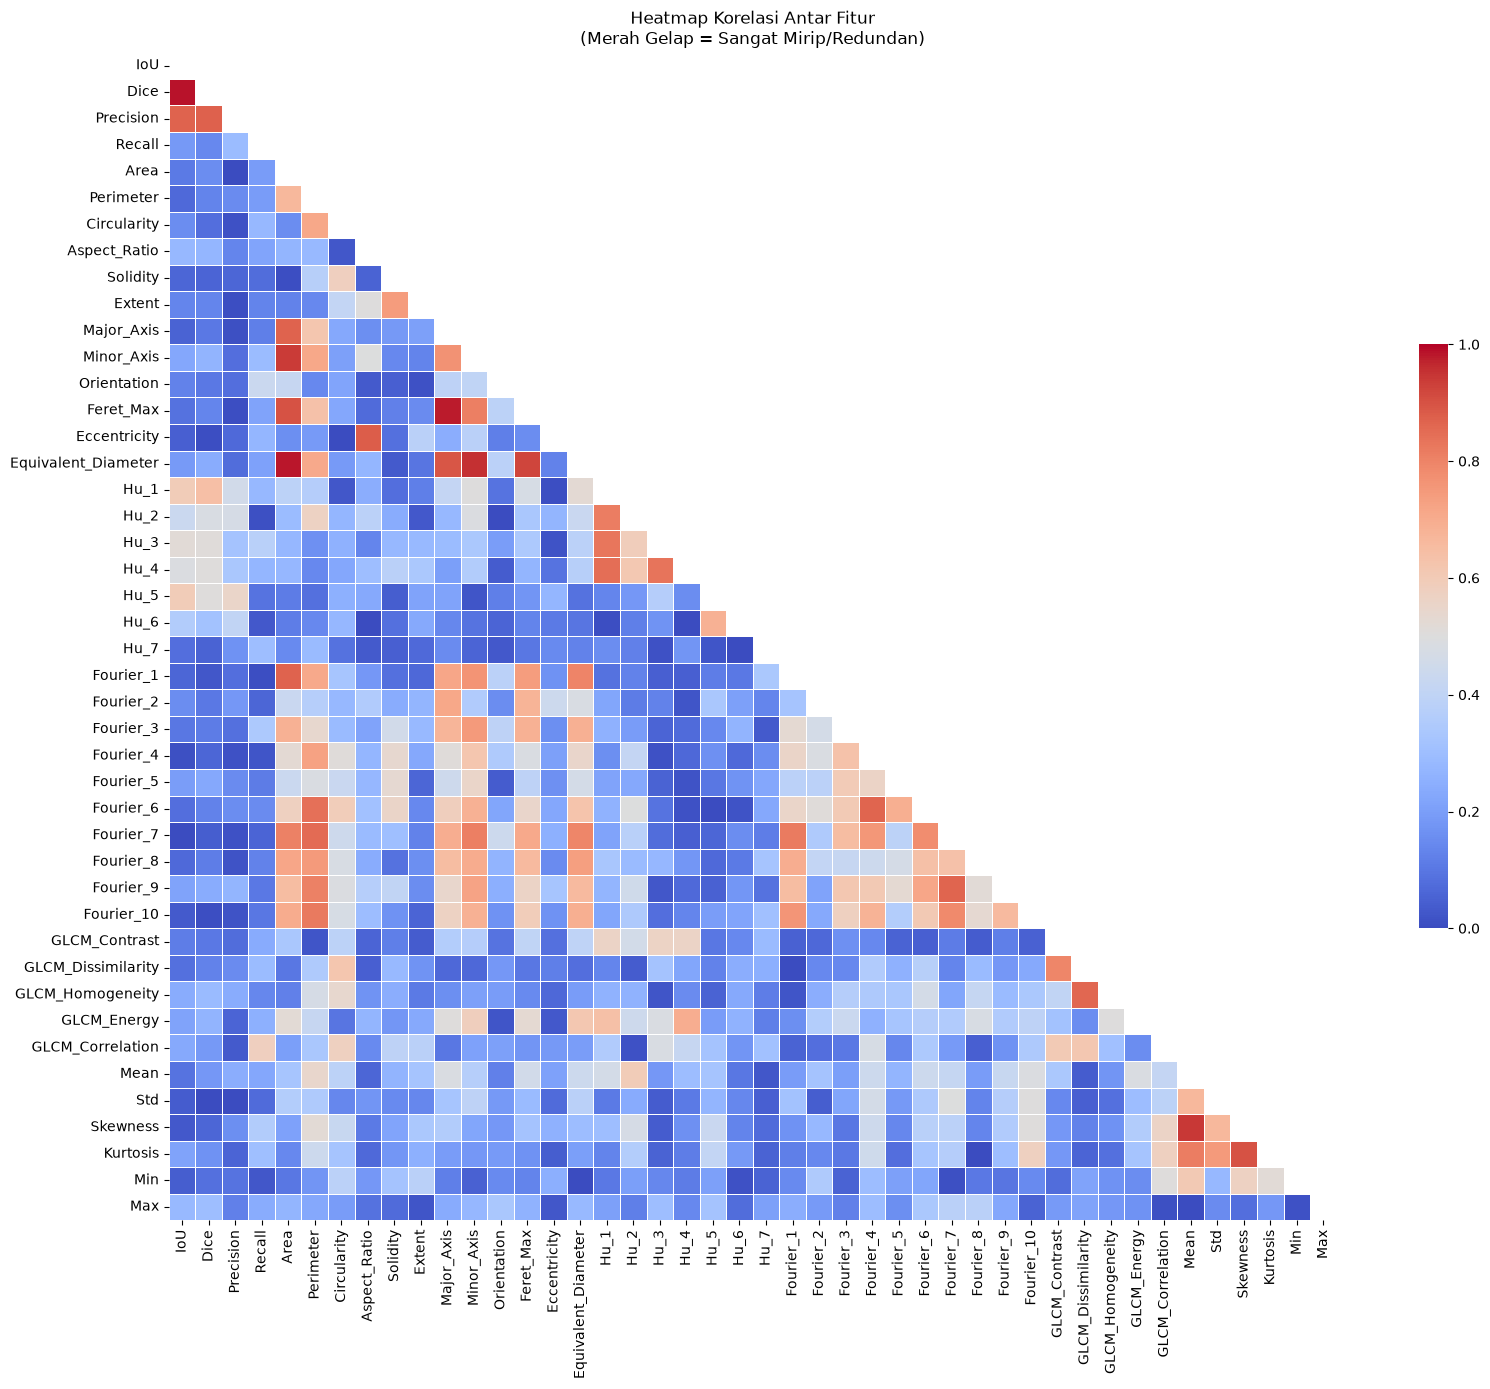

Ditemukan 4 pasangan fitur yang sangat redundan (korelasi > 0.95).
Contoh 5 pasangan:
  - IoU  <-->  Dice
  - Area  <-->  Equivalent_Diameter
  - Major_Axis  <-->  Feret_Max
  - Minor_Axis  <-->  Equivalent_Diameter




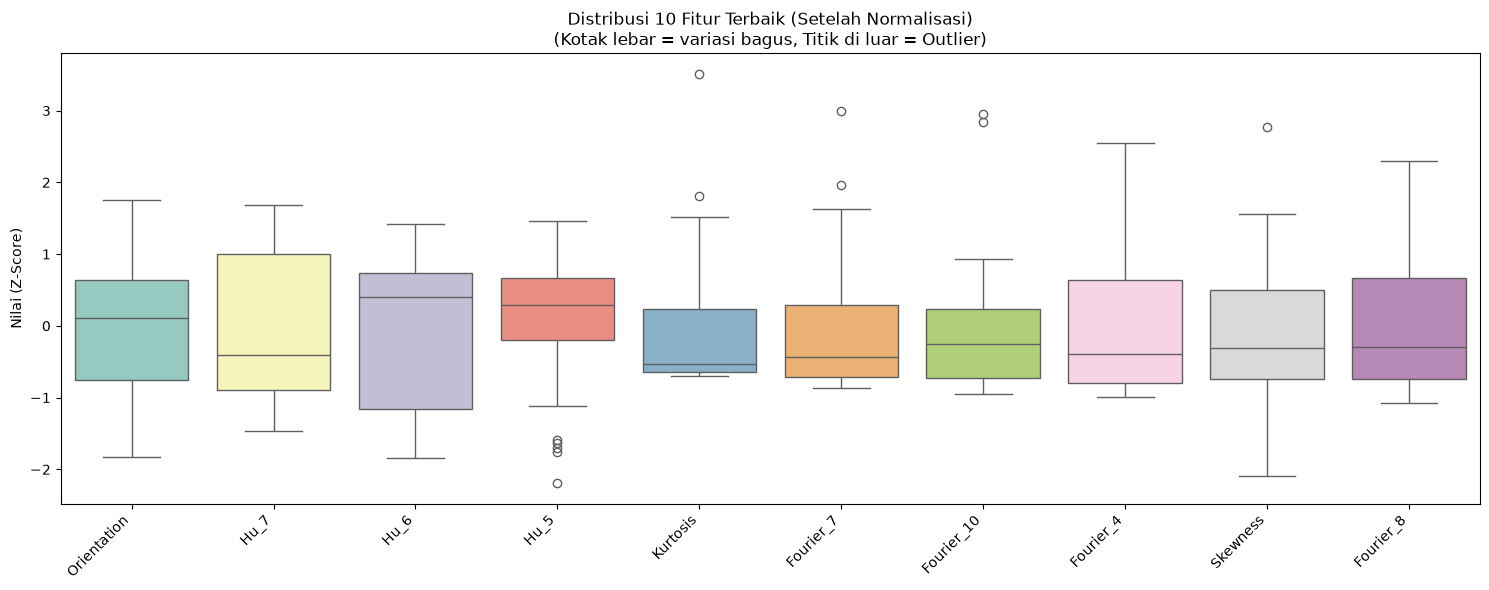

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# 1. Load Data CSV
csv_path = "Berhasil/fitur_lengkap_polip.csv"
df = pd.read_csv(csv_path)

# Pisahkan kolom nama file dan kolom numerik
df_num = df.drop(columns=['Filename'])

print(f"Total data: {df.shape[0]} gambar")
print(f"Total fitur: {df_num.shape[1]} kolom\n")

# ==========================================
# ANALISIS 1: FITUR MANA YANG PALING BERVARIASI?
# ==========================================
# Kita hitung Coefficient of Variation (CV) = Std / Mean
# Kenapa CV? Karena skala fitur beda-beda (Area jutaan, Solidity 0-1)
# CV membuat semua fitur seimbang untuk dibandingkan.

cv_scores = (df_num.std() / df_num.mean().abs()).sort_values(ascending=False)

plt.figure(figsize=(12, 6))
cv_scores.head(15).plot(kind='bar', color='teal')
plt.title("Top 15 Fitur dengan Variasi Tertinggi (Coefficient of Variation)\n(Semakin tinggi = semakin bagus untuk membedakan objek)")
plt.ylabel("CV Score")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("5 Fitur Paling Bervariasi:")
print(cv_scores.head(5))
print("\n" + "="*50 + "\n")

# ==========================================
# ANALISIS 2: FITUR MANA YANG REDUNDAN (SALING TINDIH)?
# ==========================================
# Kita buat Heatmap Korelasi. 
# Jika ada 2 fitur yang kotaknya merah gelap/biru gelap (nilai > 0.9 atau < -0.9),
# artinya mereka memberikan informasi yang SAMA. Cukup pilih salah satu.

plt.figure(figsize=(18, 14))
corr_matrix = df_num.corr().abs()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) # Sembunyikan segitiga atas
sns.heatmap(corr_matrix, mask=mask, cmap='coolwarm', vmax=1.0, vmin=0.0, 
            square=True, linewidths=.5, cbar_kws={"shrink": .5})
plt.title("Heatmap Korelasi Antar Fitur\n(Merah Gelap = Sangat Mirip/Redundan)")
plt.tight_layout()
plt.show()

# Cari pasangan fitur yang korelasinya > 0.95
high_corr = np.where(corr_matrix > 0.95)
high_corr_pairs = [(corr_matrix.index[x], corr_matrix.columns[y]) 
                   for x, y in zip(*high_corr) if x != y and x < y]

print(f"Ditemukan {len(high_corr_pairs)} pasangan fitur yang sangat redundan (korelasi > 0.95).")
print("Contoh 5 pasangan:")
for pair in high_corr_pairs[:5]:
    print(f"  - {pair[0]}  <-->  {pair[1]}")
print("\n" + "="*50 + "\n")

# ==========================================
# ANALISIS 3: DISTRIBUSI FITUR (BOXPLOT)
# ==========================================
# Kita lihat sebaran 10 fitur teratas dari Analisis 1
top_features = cv_scores.head(10).index.tolist()

# Normalisasi data agar bisa diplot dalam satu grafik (karena skalanya beda jauh)
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df_num[top_features]), columns=top_features)

plt.figure(figsize=(15, 6))
sns.boxplot(data=df_scaled, palette="Set3")
plt.title("Distribusi 10 Fitur Terbaik (Setelah Normalisasi)\n(Kotak lebar = variasi bagus, Titik di luar = Outlier)")
plt.xticks(rotation=45, ha='right')
plt.ylabel("Nilai (Z-Score)")
plt.tight_layout()
plt.show()

                       Nilai
GLCM_Contrast       1.435381
GLCM_Dissimilarity  0.143307
GLCM_Homogeneity    0.966435
GLCM_Energy         0.806284
GLCM_Correlation    0.991350
GLCM_ASM            0.650094


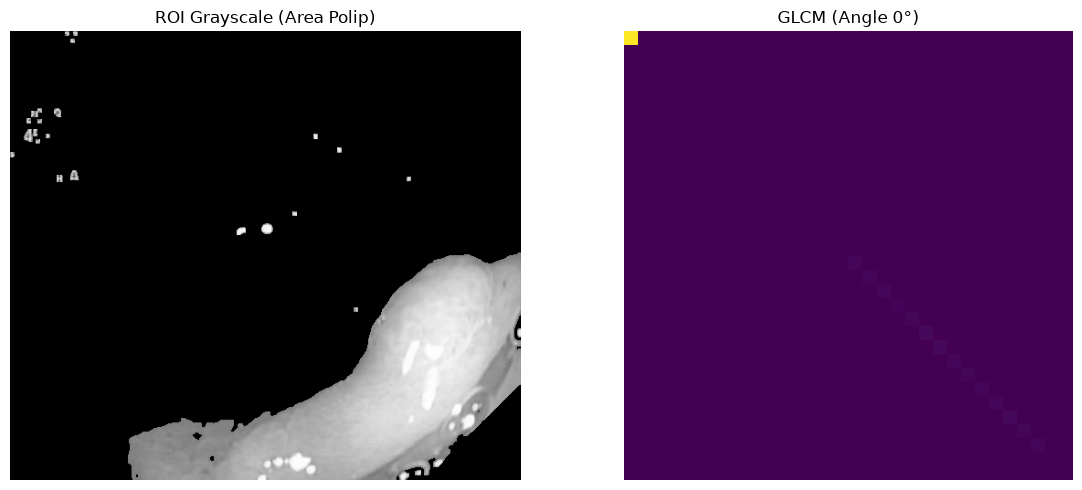

In [ ]:
gray_img = cv2.cvtColor(seg, cv2.COLOR_RGB2GRAY)
x, y, w, h = cv2.boundingRect(mask)
roi_gray = gray_img[y:y+h, x:x+w]
roi_mask = mask[y:y+h, x:x+w]

# Kuantisasi 32 level
roi_quant = (roi_gray // 8).astype(np.uint8)
glcm = graycomatrix(roi_quant, distances=[1], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4], levels=32, symmetric=True, normed=True)

texture_data = {
    "GLCM_Contrast": graycoprops(glcm, 'contrast').mean(),
    "GLCM_Dissimilarity": graycoprops(glcm, 'dissimilarity').mean(),
    "GLCM_Homogeneity": graycoprops(glcm, 'homogeneity').mean(),
    "GLCM_Energy": graycoprops(glcm, 'energy').mean(),
    "GLCM_Correlation": graycoprops(glcm, 'correlation').mean(),
    "GLCM_ASM": graycoprops(glcm, 'ASM').mean(),
}
print(pd.DataFrame([texture_data]).T.rename(columns={0: "Nilai"}))

# Visualisasi GLCM Matrix
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(roi_gray, cmap='gray'); ax[0].set_title("ROI Grayscale (Area Polip)"); ax[0].axis('off')
ax[1].imshow(np.log1p(glcm[:, :, 0, 0]), cmap='viridis'); ax[1].set_title("GLCM (Angle 0°)"); ax[1].axis('off')
plt.tight_layout(); plt.show()